# PROJETO DE COLETA DE DADOS
## Pokémon via PokeAPI — 1ª geração + stats

**Autor:** Rodrigo Gimenes Rodrigues  
**Matrícula:** CP3071782  
**Data:** 2026-11-08  
**Disciplina:** Processamento e Coleta de Dados  

---

## 1. OBJETIVO
Coletar os 151 Pokémon da 1ª geração pela PokeAPI, incluindo stats de combate, limpar os dados e montar um dataset próprio.

## 2. FONTES DE DADOS
| Fonte | URL | Método | Dados Coletados |
|-------|-----|--------|-----------------|
| PokeAPI | https://pokeapi.co/api/v2/pokemon | API REST | atributos gerais + HP, ataque, defesa, sp. atk, sp. def, velocidade |


## 3. METODOLOGIA

### 3.1 Coleta
Lista com `limit=151` e, em seguida, uma requisição de detalhe por Pokémon.

### 3.2 Limpeza
Conversão de unidades, padronização de nomes, nulos do tipo secundário, criação de `total_stats` e remoção de duplicatas.

### 3.3 Processamento
DataFrame final ordenado por id e exportado em CSV.


## 3.1 Código de coleta

In [1]:
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt

url_lista = 'https://pokeapi.co/api/v2/pokemon?limit=151'
resposta = requests.get(url_lista, timeout=30)
resposta.raise_for_status()
lista = resposta.json()['results']

registros = []
for i, item in enumerate(lista, start=1):
    det = requests.get(item['url'], timeout=30).json()
    tipos = [t['type']['name'] for t in det['types']]
    stats = {s['stat']['name']: s['base_stat'] for s in det['stats']}

    registros.append({
        'id': det['id'],
        'nome': det['name'],
        'altura_dm': det['height'],
        'peso_hg': det['weight'],
        'experiencia_base': det['base_experience'],
        'tipo_principal': tipos[0] if tipos else None,
        'tipo_secundario': tipos[1] if len(tipos) > 1 else None,
        'hp': stats.get('hp'),
        'ataque': stats.get('attack'),
        'defesa': stats.get('defense'),
        'ataque_especial': stats.get('special-attack'),
        'defesa_especial': stats.get('special-defense'),
        'velocidade': stats.get('speed'),
        'qtd_habilidades': len(det['abilities']),
        'qtd_movimentos': len(det['moves']),
    })

    if i % 25 == 0:
        print(f'Coletados: {i}/{len(lista)}')
        time.sleep(0.2)

df_bruto = pd.DataFrame(registros)
df_bruto.to_csv('pokemon_bruto.csv', index=False, encoding='utf-8')
print('Registros coletados:', len(df_bruto))
df_bruto.head()

Coletados: 25/151


Coletados: 50/151


Coletados: 75/151


Coletados: 100/151


Coletados: 125/151


Coletados: 150/151


Registros coletados: 151


,id,nome,altura_dm,peso_hg,experiencia_base,tipo_principal,tipo_secundario,hp,ataque,defesa,ataque_especial,defesa_especial,velocidade,qtd_habilidades,qtd_movimentos
0,1,bulbasaur,7,69,64,grass,poison,45,49,49,65,65,45,2,86
1,2,ivysaur,10,130,142,grass,poison,60,62,63,80,80,60,2,83
2,3,venusaur,20,1000,236,grass,poison,80,82,83,100,100,80,2,97
3,4,charmander,6,85,62,fire,NaN,39,52,43,60,50,65,2,105
4,5,charmeleon,11,190,142,fire,NaN,58,64,58,80,65,80,2,103


## 3.2 Limpeza e processamento

In [2]:
df = df_bruto.copy()

df['nome'] = df['nome'].str.strip().str.title()
df['altura_m'] = pd.to_numeric(df['altura_dm'], errors='coerce') / 10
df['peso_kg'] = pd.to_numeric(df['peso_hg'], errors='coerce') / 10

for col in ['experiencia_base', 'hp', 'ataque', 'defesa',
            'ataque_especial', 'defesa_especial', 'velocidade']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['total_stats'] = (
    df['hp'] + df['ataque'] + df['defesa']
    + df['ataque_especial'] + df['defesa_especial'] + df['velocidade']
)
df['tipo_secundario'] = df['tipo_secundario'].fillna('nenhum')
df = df.drop_duplicates(subset=['id'])

df = df[['id', 'nome', 'altura_m', 'peso_kg', 'experiencia_base',
         'tipo_principal', 'tipo_secundario', 'hp', 'ataque', 'defesa',
         'ataque_especial', 'defesa_especial', 'velocidade', 'total_stats',
         'qtd_habilidades', 'qtd_movimentos']]
df = df.sort_values('id').reset_index(drop=True)

print('Nulos por coluna:')
print(df.isnull().sum())
df.head()

Nulos por coluna:
id                  0
nome                0
altura_m            0
peso_kg             0
experiencia_base    0
tipo_principal      0
tipo_secundario     0
hp                  0
ataque              0
defesa              0
ataque_especial     0
defesa_especial     0
velocidade          0
total_stats         0
qtd_habilidades     0
qtd_movimentos      0
dtype: int64


,id,nome,altura_m,peso_kg,experiencia_base,tipo_principal,tipo_secundario,hp,ataque,defesa,ataque_especial,defesa_especial,velocidade,total_stats,qtd_habilidades,qtd_movimentos
0,1,Bulbasaur,0.7,6.9,64,grass,poison,45,49,49,65,65,45,318,2,86
1,2,Ivysaur,1.0,13.0,142,grass,poison,60,62,63,80,80,60,405,2,83
2,3,Venusaur,2.0,100.0,236,grass,poison,80,82,83,100,100,80,525,2,97
3,4,Charmander,0.6,8.5,62,fire,nenhum,39,52,43,60,50,65,309,2,105
4,5,Charmeleon,1.1,19.0,142,fire,nenhum,58,64,58,80,65,80,405,2,103


## 4. DATASET FINAL

In [3]:
print('Shape:', df.shape)
print('Colunas:', df.columns.tolist())
print(df.dtypes)
df.to_csv('pokemon_dataset.csv', index=False, encoding='utf-8')
print('CSV salvo: pokemon_dataset.csv')
df.head(10)

Shape: (151, 16)
Colunas: ['id', 'nome', 'altura_m', 'peso_kg', 'experiencia_base', 'tipo_principal', 'tipo_secundario', 'hp', 'ataque', 'defesa', 'ataque_especial', 'defesa_especial', 'velocidade', 'total_stats', 'qtd_habilidades', 'qtd_movimentos']
id                    int64
nome                    str
altura_m            float64
peso_kg             float64
experiencia_base      int64
tipo_principal          str
tipo_secundario         str
hp                    int64
ataque                int64
defesa                int64
ataque_especial       int64
defesa_especial       int64
velocidade            int64
total_stats           int64
qtd_habilidades       int64
qtd_movimentos        int64
dtype: object
CSV salvo: pokemon_dataset.csv


,id,nome,altura_m,peso_kg,experiencia_base,tipo_principal,tipo_secundario,hp,ataque,defesa,ataque_especial,defesa_especial,velocidade,total_stats,qtd_habilidades,qtd_movimentos
0,1,Bulbasaur,0.7,6.9,64,grass,poison,45,49,49,65,65,45,318,2,86
1,2,Ivysaur,1.0,13.0,142,grass,poison,60,62,63,80,80,60,405,2,83
2,3,Venusaur,2.0,100.0,236,grass,poison,80,82,83,100,100,80,525,2,97
3,4,Charmander,0.6,8.5,62,fire,nenhum,39,52,43,60,50,65,309,2,105
4,5,Charmeleon,1.1,19.0,142,fire,nenhum,58,64,58,80,65,80,405,2,103
5,6,Charizard,1.7,90.5,240,fire,flying,78,84,78,109,85,100,534,2,131
6,7,Squirtle,0.5,9.0,63,water,nenhum,44,48,65,50,64,43,314,2,105
7,8,Wartortle,1.0,22.5,142,water,nenhum,59,63,80,65,80,58,405,2,101
8,9,Blastoise,1.6,85.5,239,water,nenhum,79,83,100,85,105,78,530,2,121
9,10,Caterpie,0.3,2.9,39,bug,nenhum,45,30,35,20,20,45,195,2,5


## 5. ANÁLISE EXPLORATÓRIA

In [4]:
print(df.describe())
print()
print('Tipos principais:')
print(df['tipo_principal'].value_counts())
print()
print('Top 5 por total_stats:')
print(df.nlargest(5, 'total_stats')[['nome', 'tipo_principal', 'total_stats']])

               id    altura_m     peso_kg  experiencia_base          hp  \
count  151.000000  151.000000  151.000000        151.000000  151.000000   
mean    76.000000    1.194702   45.951656        135.052980   64.211921   
std     43.734045    0.962621   59.447988         67.719794   28.590117   
min      1.000000    0.200000    0.100000         39.000000   10.000000   
25%     38.500000    0.700000    9.900000         65.000000   45.000000   
50%     76.000000    1.000000   30.000000        142.000000   60.000000   
75%    113.500000    1.500000   56.250000        176.000000   80.000000   
max    151.000000    8.800000  460.000000        395.000000  250.000000   

           ataque      defesa  ataque_especial  defesa_especial  velocidade  \
count  151.000000  151.000000       151.000000       151.000000  151.000000   
mean    72.913907   68.225166        67.139073        66.086093   69.066225   
std     26.755421   26.916704        28.534199        24.208797   27.024598   
min     

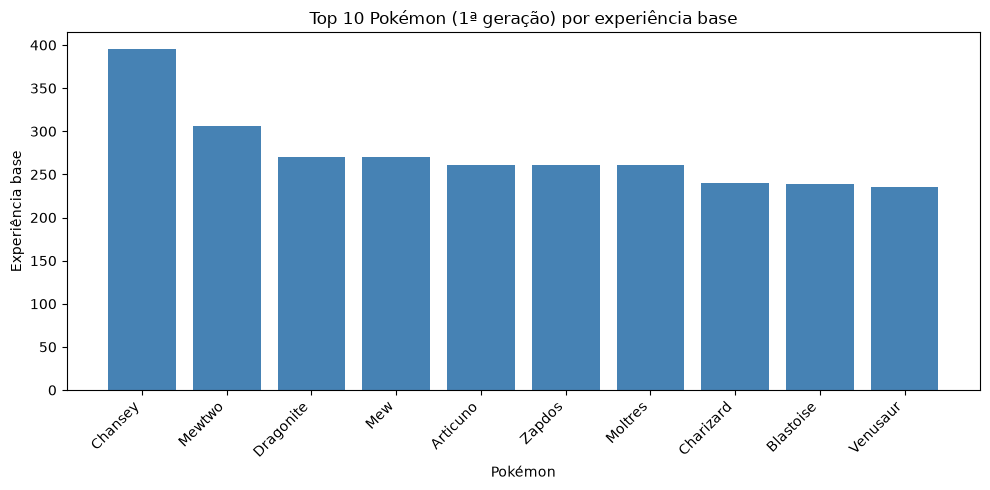

In [5]:
top = df.nlargest(10, 'experiencia_base')

plt.figure(figsize=(10, 5))
plt.bar(top['nome'], top['experiencia_base'], color='steelblue')
plt.title('Top 10 Pokémon (1ª geração) por experiência base')
plt.xlabel('Pokémon')
plt.ylabel('Experiência base')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

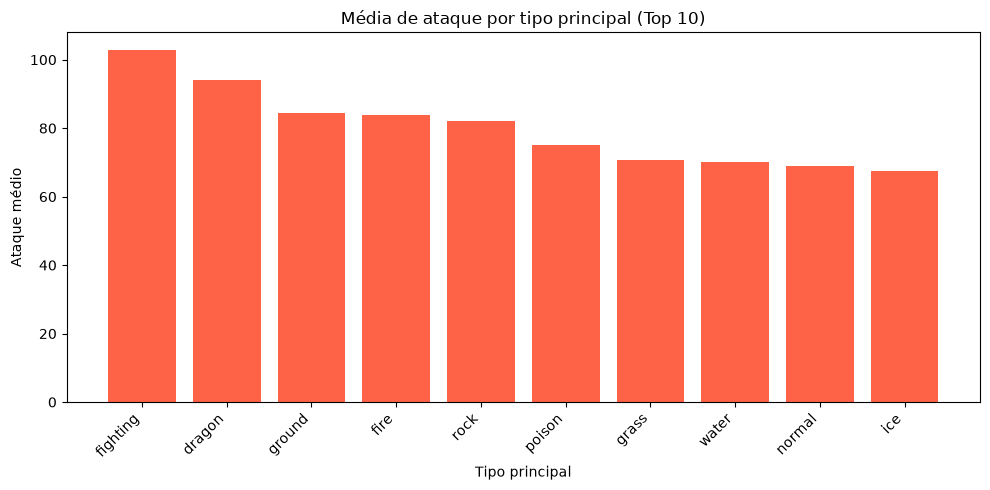

In [6]:
media_atk = (
    df.groupby('tipo_principal')['ataque']
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 5))
plt.bar(media_atk.index, media_atk.values, color='tomato')
plt.title('Média de ataque por tipo principal (Top 10)')
plt.xlabel('Tipo principal')
plt.ylabel('Ataque médio')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 6. INSIGHTS
1. Na 1ª geração, a média de experiência base ficou em torno de **135.1**.
2. Maior experiência nesta coleta: **Chansey** (395).
3. Maior total de stats: **Mewtwo** (680).
4. Tipo principal mais comum: **water**.
5. Tipo com maior ataque médio: **fighting**.

## 7. LIMITAÇÕES
- Apenas a 1ª geração (151)
- Coleta pontual
- Sem formas alternativas / megas

## 8. PRÓXIMOS PASSOS
- Incluir outras gerações
- Cruzar com efetividade de tipos
- Criar ranking por função de combate

## 9. ARQUIVOS GERADOS
- `pokemon_bruto.csv`
- `pokemon_dataset.csv`
- `documentacao.md`
- `grafico_experiencia_base.png`
- `grafico_ataque_por_tipo.png`

## 10. REFERÊNCIAS
- https://pokeapi.co/
- https://docs.python-requests.org/
- https://pandas.pydata.org/
